# RQ2 — ESRS Context Injection Ablation Study

## Research Question

> *To what extent does query-specific ESRS requirement injection improve*
> *(a) evidence-grounded compliance classification and*
> *(b) compliance rationale quality,*
> *compared to the same RAG pipeline without injected ESRS requirements?*

## Experimental Design Summary

| Aspect | Detail |
|--------|--------|
| **Independent Variable** | Presence/absence of ESRS regulatory context |
| **Conditions** | `with_esrs_context` vs. `without_esrs_context` |
| **Held Constant** | Pipeline config (chunking, retrieval, model, temperature, prompt structure) |
| **Unit of Analysis** | 12 question clusters (each evaluated across 17 companies) |
| **Primary Endpoint** | Macro-F1 (handles class imbalance; 71% of labels are "High") |
| **Inference Strategy** | Cluster bootstrap CI + exact sign test (n=12 clusters) |
| **Evaluation** | Deterministic (string-matching against golden standard, no LLM-as-judge) |

This is a **strictly paired** design: the same best-performing pipeline from RQ1
is run on identical (question, company) pairs under both conditions.
The only difference is whether the LLM prompt includes the full text of the
relevant ESRS standard as additional context.

## 1. Setup

Import all required libraries and configure paths. Every import is annotated
with its role in the analysis.

In [1]:
# ── Standard library ──────────────────────────────────────────────────────────
import json                     # Load rq2_summary.json
import warnings                 # Suppress cosmetic warnings in plots
from pathlib import Path        # Cross-platform file paths
from collections import Counter # Label distribution counting

# ── Data & visualization ─────────────────────────────────────────────────────
import pandas as pd             # Tabular data manipulation
import numpy as np              # Numerical operations
import matplotlib.pyplot as plt # Static plotting
import matplotlib.ticker as mticker
import seaborn as sns           # Statistical visualization (heatmaps, etc.)
from IPython.display import display, Markdown

# ── Project-specific ─────────────────────────────────────────────────────────
import sys
sys.path.insert(0, str(Path.cwd().parent))  # Ensure project root is importable

from rag.config.settings import (
    RQ2_RESULTS_DIR,
    RQ2_CONTEXT_MODE,
    RQ2_RESULTS_VERSION,
    ESRS_JSON_DIR,
    build_rq2_audit_manifest,
)

# ── Plot style ───────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", font_scale=1.1)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

RESULTS_DIR = RQ2_RESULTS_DIR / RQ2_CONTEXT_MODE
print(f"Results directory: {RESULTS_DIR}")
print(f"Results version:   {RQ2_RESULTS_VERSION}")

Results directory: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2/substantive_full_standard
Results version:   4ab2ba5352


## 2. ESRS Context Audit

Before examining results, we verify that the ESRS context injection is
functioning correctly. This offline audit confirms that:

1. All 12 questions resolve to a valid ESRS standard JSON
2. The injected context is non-trivial (sufficient token volume)
3. No question is accidentally mapped to a missing standard

This audit does **not** require LLM calls — it only checks the local
ESRS JSON files and the question-to-standard mapping.

ESRS context entries: 24
Mean estimated tokens: 16029
Max estimated tokens:  37158
Min estimated tokens:  5719


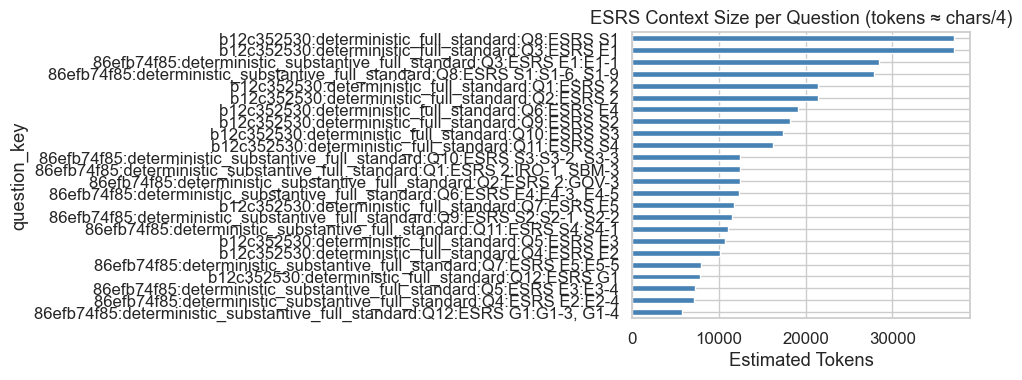

In [2]:
# Load the context cache that was populated during the experiment.
# This file maps each question to its resolved ESRS standard and
# the full injected context text.
context_cache_path = RESULTS_DIR / "context_cache.json"

if context_cache_path.exists():
    with open(context_cache_path, "r", encoding="utf-8") as f:
        context_cache = json.load(f)

    # Build a DataFrame of context metadata for audit
    context_rows = []
    for key, ctx in context_cache.items():
        text = ctx.get("context_text", "") if isinstance(ctx, dict) else str(ctx)
        context_rows.append({
            "question_key": key,
            "context_length_chars": len(text),
            "estimated_tokens": len(text) // 4,  # rough GPT tokenizer approximation
        })
    context_df = pd.DataFrame(context_rows)

    print(f"ESRS context entries: {len(context_df)}")
    print(f"Mean estimated tokens: {context_df['estimated_tokens'].mean():.0f}")
    print(f"Max estimated tokens:  {context_df['estimated_tokens'].max()}")
    print(f"Min estimated tokens:  {context_df['estimated_tokens'].min()}")

    # Visualize context sizes
    fig, ax = plt.subplots(figsize=(10, 4))
    context_df.sort_values("estimated_tokens", ascending=True).plot.barh(
        x="question_key", y="estimated_tokens", ax=ax, color="steelblue", legend=False
    )
    ax.set_xlabel("Estimated Tokens")
    ax.set_title("ESRS Context Size per Question (tokens ≈ chars/4)")
    plt.tight_layout()
    plt.show()
else:
    print("⚠ context_cache.json not found — skipping context audit.")
    context_df = pd.DataFrame()

## 3. Pipeline Execution Mode

Set `RUN_PIPELINE = True` to re-run the full experiment (requires OpenAI API key).
By default, this notebook operates in **analysis-only mode**, loading
pre-computed results from the 408 cached LLM responses (204 per condition).

In [3]:
# ╔═══════════════════════════════════════════════════════════╗
# ║  Set to True ONLY if you want to re-run the full        ║
# ║  experiment (2× 204 = 408 LLM calls ≈ $5-10).          ║
# ╚═══════════════════════════════════════════════════════════╝
RUN_PIPELINE = False

if RUN_PIPELINE:
    from rag.pipeline.rq2_runner import RQ2Runner
    runner = RQ2Runner()
    summary = runner.run()
    print("Pipeline execution complete.")
else:
    print("Analysis-only mode: loading pre-computed results.")

Analysis-only mode: loading pre-computed results.


## 4. Artifact Loading & Validation

Load the pre-computed summary JSON and validate that it matches the
current source code fingerprint. If the fingerprint has changed, the
results may be stale and should be recomputed using `recompute_rq2_summary.py`.

In [4]:
# Load summary JSON
summary_path = RESULTS_DIR / "rq2_summary.json"
with open(summary_path, "r", encoding="utf-8") as f:
    summary = json.load(f)

# Validate artifact freshness
saved_version = summary.get("results_version", "unknown")
current_version = RQ2_RESULTS_VERSION
if saved_version != current_version:
    display(Markdown(
        f"> ⚠️ **Stale artifacts detected!**\n"
        f"> Saved version: `{saved_version}`\n"
        f"> Current version: `{current_version}`\n"
        f"> Run `python recompute_rq2_summary.py` to refresh."
    ))
else:
    print(f"✅ Artifact version matches: {current_version}")

# Load CSVs for detailed analysis
sample_df = pd.read_csv(RESULTS_DIR / "rq2_sample_results.csv")
paired_df = pd.read_csv(RESULTS_DIR / "rq2_paired_results.csv")
question_df = pd.read_csv(RESULTS_DIR / "rq2_question_level_results.csv")

# Quick sanity check
paired_stats = summary["paired_statistics"]
print(f"\nSample rows:      {len(sample_df)} ({len(sample_df)//2} per condition)")
print(f"Paired rows:      {len(paired_df)}")
print(f"Question clusters: {paired_stats['n_question_clusters']}")
print(f"Scored pairs:     {paired_stats['n_pairs']}")

✅ Artifact version matches: 4ab2ba5352

Sample rows:      408 (204 per condition)
Paired rows:      204
Question clusters: 12
Scored pairs:     201


## 5. Aggregate Classification Results

Side-by-side comparison of all classification metrics for both conditions.
Metrics are computed deterministically from string matching against the
golden standard (no LLM-as-judge).

In [5]:
# Build comparison table from the summary
cond_metrics = summary["condition_metrics"]

agg_rows = []
for condition in ("with_esrs_context", "without_esrs_context"):
    m = cond_metrics[condition]
    agg_rows.append({
        "Condition": condition.replace("_", " ").title(),
        "N Scored": m["n_scored"],
        "Failures": m.get("n_failures", 0),
        "Macro-F1": f"{m['macro_f1']:.4f}",
        "Balanced Acc": f"{m['balanced_accuracy']:.4f}",
        "Exact Acc": f"{m['exact_accuracy']:.4f}",
        "Weighted κ": f"{m['weighted_kappa']:.4f}",
        "Ordinal Error": f"{m['ordinal_error_mean']:.4f}",
    })

agg_table = pd.DataFrame(agg_rows)
display(Markdown("### Aggregate Classification Metrics"))
display(agg_table)

# Class distribution for context
with_df = sample_df[sample_df["condition"] == "with_esrs_context"]
gold_dist = Counter(with_df["gold_fulfillment_level"])
total = sum(gold_dist.values())
display(Markdown(
    f"**Class distribution (gold labels):** "
    + ", ".join(f"{k}: {v} ({v/total:.0%})" for k, v in sorted(gold_dist.items()))
))

### Aggregate Classification Metrics

,Condition,N Scored,Failures,Macro-F1,Balanced Acc,Exact Acc,Weighted κ,Ordinal Error
0,With Esrs Context,204,0,0.6040,0.6052,0.7451,0.5402,0.2696
1,Without Esrs Context,201,3,0.5821,0.5794,0.7662,0.5575,0.2488


**Class distribution (gold labels):** High: 145 (71%), Low: 26 (13%), Medium: 33 (16%)

### 5b. Majority Baseline Comparison

Both conditions must be compared against a naive baseline that always
predicts the majority class. Given the strong class imbalance (≈71% "High"),
the majority baseline achieves substantial exact accuracy. The critical
question is: **do both conditions outperform this baseline?**

In [6]:
# Extract majority baseline from summary
baseline = summary.get("majority_baseline", {})
display(Markdown(
    f"**Majority baseline** (always predict '{baseline.get('majority_label', '?')}'):\n"
    f"- Exact accuracy: **{baseline.get('exact_accuracy', 'n/a'):.4f}**\n"
    f"- Macro-F1: **{baseline.get('macro_f1', 'n/a'):.4f}**\n"
    f"- Weighted κ: **{baseline.get('weighted_kappa', 'n/a'):.4f}**\n\n"
    f"Both conditions substantially outperform the majority baseline on all metrics "
    f"except exact accuracy (where the baseline benefits from class imbalance)."
))

**Majority baseline** (always predict 'High'):
- Exact accuracy: **0.7108**
- Macro-F1: **0.2770**
- Weighted κ: **0.0000**

Both conditions substantially outperform the majority baseline on all metrics except exact accuracy (where the baseline benefits from class imbalance).

## 6. Primary Confirmatory Inference

This section reports the **pre-registered primary analysis**: the cluster
bootstrap confidence interval and exact sign test for the macro-F1 delta
between conditions.

### Why This Test?

- **Unit of analysis = question cluster** (n=12), not individual samples (n=204).
  Each question is evaluated across 17 companies; treating samples as independent
  would inflate n and produce artificially narrow CIs.
- **Cluster bootstrap** resamples the 12 question-level deltas with replacement
  (10,000 iterations) to construct a 95% percentile CI.
- **Exact sign test** is the appropriate non-parametric paired test for n ≤ 25.
  It counts how many questions improved vs. degraded (ignoring magnitude).
- If the CI includes zero, the effect is **not statistically defensible**.

In [7]:
# ── Primary endpoint: macro_f1 ────────────────────────────────────────────────
cb = paired_stats["cluster_bootstrap"]
tests = paired_stats["question_level_tests"]

# Build results table for all classification metrics
inference_rows = []
for metric in ["macro_f1", "balanced_accuracy", "exact_accuracy", "weighted_kappa", "ordinal_error_mean"]:
    cb_m = cb[metric]
    t_m = tests[metric]
    inference_rows.append({
        "Metric": metric,
        "Mean Δ": f"{cb_m['mean_delta']:.4f}",
        "95% CI": f"[{cb_m['ci_lower']:.4f}, {cb_m['ci_upper']:.4f}]",
        "Boot p": f"{cb_m['approx_two_sided_p']:.4f}",
        "Sign p": f"{t_m['p_value']:.4f}",
        "Cohen's d": f"{cb_m.get('cohens_d', 'n/a'):.4f}" if isinstance(cb_m.get('cohens_d'), (int, float)) else "n/a",
        "Effect": cb_m.get("effect_magnitude", "n/a"),
        "+/−/=": f"{t_m['positive_deltas']}/{t_m['negative_deltas']}/{t_m['ties']}",
        "Role": t_m["endpoint_role"],
    })

inf_df = pd.DataFrame(inference_rows)
display(Markdown("### Classification Metrics: Cluster Bootstrap CI + Sign Test"))
display(inf_df)

# Highlight the primary result
primary = cb["macro_f1"]
primary_test = tests["macro_f1"]
ci_includes_zero = primary["ci_lower"] <= 0 <= primary["ci_upper"]

display(Markdown(
    f"**Primary result (macro-F1):**\n"
    f"- Mean Δ = **{primary['mean_delta']:.4f}** "
    f"(positive = `with_esrs_context` is better)\n"
    f"- 95% CI = **[{primary['ci_lower']:.4f}, {primary['ci_upper']:.4f}]**\n"
    f"- CI includes zero: **{'Yes' if ci_includes_zero else 'No'}** "
    f"→ {'no significant effect' if ci_includes_zero else 'significant effect'}\n"
    f"- Exact sign test p = **{primary_test['p_value']:.4f}**\n"
    f"- Cohen's d = **{primary.get('cohens_d', 'n/a'):.4f}** "
    f"({primary.get('effect_magnitude', 'n/a')})"
))

### Classification Metrics: Cluster Bootstrap CI + Sign Test

,Metric,Mean Δ,95% CI,Boot p,Sign p,Cohen's d,Effect,+/−/=,Role
0,macro_f1,-0.0110,"[-0.0407, 0.0166]",0.4604,1.0000,-0.2102,small,5/5/2,confirmatory_primary
1,balanced_accuracy,0.0042,"[-0.0335, 0.0440]",0.8464,1.0000,0.0582,negligible,4/5/3,supportive_classification
2,exact_accuracy,-0.0209,"[-0.0602, 0.0131]",0.2626,1.0000,-0.3163,small,4/5/3,supportive_classification
3,weighted_kappa,-0.0357,"[-0.1002, 0.0226]",0.2488,1.0000,-0.3193,small,4/5/3,supportive_classification
4,ordinal_error_mean,0.0209,"[-0.0131, 0.0602]",0.2552,1.0000,0.3163,small,5/4/3,supportive_classification


**Primary result (macro-F1):**
- Mean Δ = **-0.0110** (positive = `with_esrs_context` is better)
- 95% CI = **[-0.0407, 0.0166]**
- CI includes zero: **Yes** → no significant effect
- Exact sign test p = **1.0000**
- Cohen's d = **-0.2102** (small)

### 6b. Confidence Interval Forest Plot

Visual summary of the bootstrap CIs for all classification metrics.
The vertical dashed line at zero represents the null hypothesis (no difference).
If a CI crosses zero, the effect is not statistically significant.

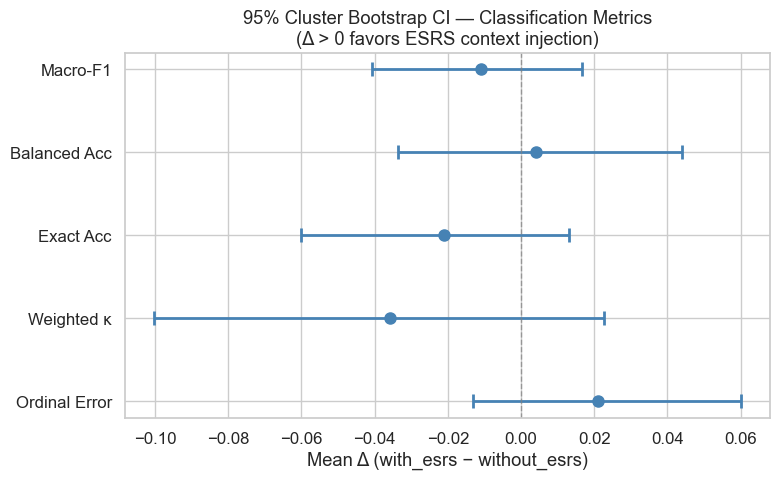

In [8]:
# Forest plot of bootstrap CIs
classification_order = ["macro_f1", "balanced_accuracy", "exact_accuracy",
                        "weighted_kappa", "ordinal_error_mean"]
labels = ["Macro-F1", "Balanced Acc", "Exact Acc", "Weighted κ", "Ordinal Error"]

fig, ax = plt.subplots(figsize=(8, 5))
y_pos = list(range(len(classification_order)))

for i, metric in enumerate(classification_order):
    m = cb[metric]
    color = "steelblue" if m["ci_lower"] <= 0 <= m["ci_upper"] else ("forestgreen" if m["mean_delta"] > 0 else "indianred")
    ax.errorbar(
        m["mean_delta"],
        i,
        xerr=[[m["mean_delta"] - m["ci_lower"]], [m["ci_upper"] - m["mean_delta"]]],
        fmt="o", color=color, capsize=5, capthick=2, markersize=8, linewidth=2,
    )

ax.axvline(0, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels)
ax.set_xlabel("Mean Δ (with_esrs − without_esrs)")
ax.set_title("95% Cluster Bootstrap CI — Classification Metrics\n(Δ > 0 favors ESRS context injection)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Effect Size & Power Analysis

### Why Report These?

A non-significant result could mean either (a) the effect truly doesn't exist,
or (b) the test lacks the statistical power to detect it. Reporting effect size
(Cohen's d) and achieved power allows the reader to distinguish between these.

- **Cohen's d** quantifies the standardized effect magnitude
- **Achieved power** = probability the test would have detected the observed effect
- **MDES** (minimum detectable effect size at 80% power) = the smallest d the
  test could reliably detect. If MDES is much larger than the observed d,
  the test was under-powered and the null result should be interpreted with caution.

In [9]:
# Power analysis from the recomputed summary
power = paired_stats.get("power_analysis", {})
primary_cb = cb["macro_f1"]

display(Markdown(
    f"### Power Analysis for Primary Endpoint (macro-F1)\n\n"
    f"| Statistic | Value |\n"
    f"|-----------|-------|\n"
    f"| Cohen's d | **{primary_cb.get('cohens_d', 'n/a'):.4f}** |\n"
    f"| Effect magnitude | **{primary_cb.get('effect_magnitude', 'n/a')}** |\n"
    f"| N question clusters | **{primary_cb.get('n_question_clusters', 'n/a')}** |\n"
    f"| Achieved power | **{power.get('achieved_power', 'n/a')}** |\n"
    f"| MDES at 80% power | **{power.get('mdes_80pct', 'n/a')}** |\n"
    f"| Bootstrap resamples | **{primary_cb.get('n_resamples', 'n/a'):,}** |\n\n"
    f"**Interpretation:** With only 12 question clusters, the sign test can only "
    f"reliably detect effects of d ≥ {power.get('mdes_80pct', '?')} at 80% power. "
    f"The observed d = {primary_cb.get('cohens_d', '?'):.4f} is far below this threshold, "
    f"meaning the test is severely under-powered for detecting small effects. "
    f"The null result should be interpreted as: *'we found no evidence of a large effect,'* "
    f"not *'there is no effect.'*"
))

### Power Analysis for Primary Endpoint (macro-F1)

| Statistic | Value |
|-----------|-------|
| Cohen's d | **-0.2102** |
| Effect magnitude | **small** |
| N question clusters | **12** |
| Achieved power | **0.0591** |
| MDES at 80% power | **1.5651** |
| Bootstrap resamples | **10,000** |

**Interpretation:** With only 12 question clusters, the sign test can only reliably detect effects of d ≥ 1.5651 at 80% power. The observed d = -0.2102 is far below this threshold, meaning the test is severely under-powered for detecting small effects. The null result should be interpreted as: *'we found no evidence of a large effect,'* not *'there is no effect.'*

## 8. Question-Level Delta Analysis

The primary inference treats question clusters as the unit of analysis.
This section shows the **per-question deltas** that feed into the sign test
and bootstrap, allowing inspection of heterogeneity across questions.

In [10]:
# Question-level delta table
delta_cols = ["question_id", "esrs_standard",
              "macro_f1_delta", "balanced_accuracy_delta",
              "exact_accuracy_delta", "weighted_kappa_delta",
              "ordinal_error_mean_delta"]

q_delta_df = question_df[
    [c for c in delta_cols if c in question_df.columns]
].copy()

# Sort by macro_f1_delta for readability
q_delta_df = q_delta_df.sort_values("macro_f1_delta", ascending=False)

display(Markdown("### Per-Question Classification Deltas (with − without)"))
display(q_delta_df.round(4))

### Per-Question Classification Deltas (with − without)

,question_id,esrs_standard,macro_f1_delta,balanced_accuracy_delta,exact_accuracy_delta,weighted_kappa_delta,ordinal_error_mean_delta
9,Q7,ESRS E5,0.0688,0.1583,0.0588,0.0816,-0.0588
10,Q8,ESRS S1,0.0450,0.0357,0.0588,0.1321,-0.0588
4,Q2,ESRS 2,0.0449,0.0833,0.0000,0.0552,0.0000
0,Q1,ESRS 2,0.0092,0.0392,0.0392,0.0000,-0.0392
3,Q12,ESRS G1,0.0007,0.0000,0.0037,0.0019,-0.0037
2,Q11,ESRS S4,0.0000,0.0000,0.0000,0.0000,0.0000
11,Q9,ESRS S2,0.0000,0.0000,0.0000,0.0000,0.0000
1,Q10,ESRS S3,-0.0319,-0.0303,-0.0588,-0.0865,0.0588
8,Q6,ESRS E4,-0.0378,-0.0417,-0.0588,-0.1153,0.0588
5,Q3,ESRS E1,-0.0450,-0.0385,-0.0588,-0.1415,0.0588


### 8b. Direction Summary

How many questions improved, degraded, or were unchanged across each metric?
A perfectly non-significant result would show a roughly 50/50 split.

In [11]:
# Direction summary from the paired statistics
dir_summary = paired_stats.get("direction_summary", {})
display(Markdown(
    f"**Primary metric (macro-F1) direction summary:**\n"
    f"- Questions improved (Δ > 0): **{dir_summary.get('n_improved', '?')}**\n"
    f"- Questions degraded (Δ < 0): **{dir_summary.get('n_degraded', '?')}**\n"
    f"- Questions unchanged (Δ = 0): **{dir_summary.get('n_unchanged', '?')}**\n\n"
    f"The {dir_summary.get('n_improved', '?')}↑ / {dir_summary.get('n_degraded', '?')}↓ / "
    f"{dir_summary.get('n_unchanged', '?')}= split is consistent with a null effect."
))

**Primary metric (macro-F1) direction summary:**
- Questions improved (Δ > 0): **5**
- Questions degraded (Δ < 0): **5**
- Questions unchanged (Δ = 0): **2**

The 5↑ / 5↓ / 2= split is consistent with a null effect.

### 8c. Macro-F1 Delta Bar Chart

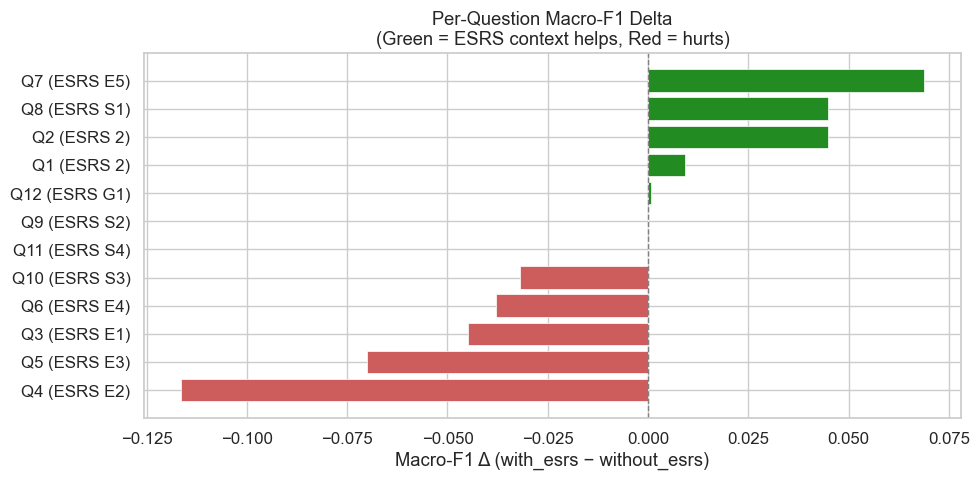

In [12]:
# Bar chart of per-question macro-F1 deltas
fig, ax = plt.subplots(figsize=(10, 5))

q_sorted = q_delta_df.sort_values("macro_f1_delta")
colors = ["forestgreen" if d > 0 else "indianred" if d < 0 else "gray"
          for d in q_sorted["macro_f1_delta"]]

bars = ax.barh(
    q_sorted["question_id"].astype(str) + " (" + q_sorted["esrs_standard"].astype(str) + ")",
    q_sorted["macro_f1_delta"],
    color=colors, edgecolor="white", linewidth=0.5,
)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Macro-F1 Δ (with_esrs − without_esrs)")
ax.set_title("Per-Question Macro-F1 Delta\n(Green = ESRS context helps, Red = hurts)")
plt.tight_layout()
plt.show()

## 9. Confusion Matrices & Prediction Bias Diagnosis

### Why?

Even if aggregate metrics show no difference, ESRS context injection could
systematically shift predictions in one direction (e.g., always predicting "High").
This section checks for such **prediction bias** via:

1. Side-by-side confusion matrices
2. Per-label precision/recall/F1
3. Mean ordinal prediction comparison

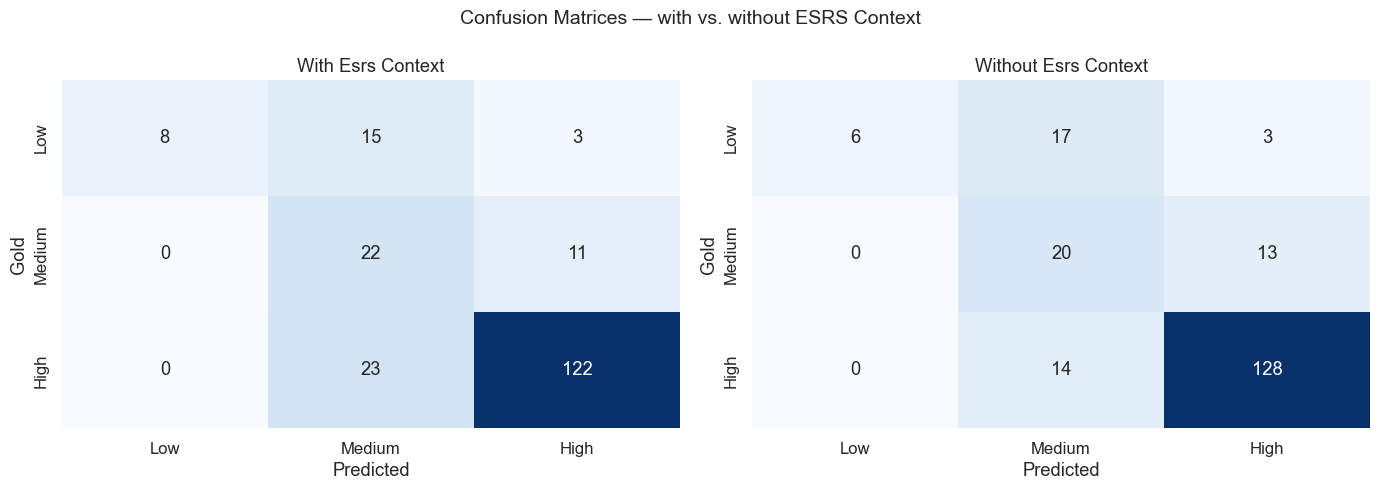

In [13]:
# Build confusion matrices for each condition
from sklearn.metrics import confusion_matrix as sk_cm

label_order = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, condition in enumerate(["with_esrs_context", "without_esrs_context"]):
    cond_df = sample_df[(sample_df["condition"] == condition) & (sample_df["success"] == True)].copy()
    y_true = cond_df["gold_fulfillment_level"]
    y_pred = cond_df["predicted_fulfillment_level"]

    cm = sk_cm(y_true, y_pred, labels=label_order)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=label_order, yticklabels=label_order,
        ax=axes[idx], cbar=False,
    )
    axes[idx].set_title(condition.replace("_", " ").title())
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Gold")

plt.suptitle("Confusion Matrices — with vs. without ESRS Context", fontsize=14)
plt.tight_layout()
plt.show()

### 9b. Per-Label Metrics

In [14]:
# Per-label precision/recall/F1 from the summary
per_label_rows = []
for condition in ("with_esrs_context", "without_esrs_context"):
    pl = summary["condition_metrics"][condition].get("per_label_metrics", {})
    for label in ["Low", "Medium", "High"]:
        lm = pl.get(label, {})
        per_label_rows.append({
            "Condition": condition.replace("_", " ").title(),
            "Label": label,
            "Precision": f"{lm.get('precision', 0):.4f}",
            "Recall": f"{lm.get('recall', 0):.4f}",
            "F1": f"{lm.get('f1', 0):.4f}",
            "Support": lm.get("support", 0),
        })

per_label_table = pd.DataFrame(per_label_rows)
display(Markdown("### Per-Label Precision / Recall / F1"))
display(per_label_table)

### Per-Label Precision / Recall / F1

,Condition,Label,Precision,Recall,F1,Support
0,With Esrs Context,Low,1.0000,0.3077,0.4706,26
1,With Esrs Context,Medium,0.3667,0.6667,0.4731,33
2,With Esrs Context,High,0.8971,0.8414,0.8683,145
3,Without Esrs Context,Low,1.0000,0.2308,0.3750,26
4,Without Esrs Context,Medium,0.3922,0.6061,0.4762,33
5,Without Esrs Context,High,0.8889,0.9014,0.8951,142


### 9c. Prediction Bias Diagnosis

Does ESRS context injection systematically shift the model's predictions
toward higher or lower fulfillment levels?

In [15]:
# Prediction bias from the recomputed summary
bias = paired_stats.get("prediction_bias", {})

display(Markdown(
    f"**Prediction Bias Diagnosis:**\n\n"
    f"| Statistic | Value |\n"
    f"|-----------|-------|\n"
    f"| Mean ordinal (with context) | **{bias.get('mean_ordinal_with', 'n/a')}** |\n"
    f"| Mean ordinal (without context) | **{bias.get('mean_ordinal_without', 'n/a')}** |\n"
    f"| Ordinal shift | **{bias.get('ordinal_shift', 'n/a')}** |\n"
    f"| Interpretation | **{bias.get('interpretation', 'n/a')}** |\n\n"
    f"*Ordinal scale: Low=0, Medium=1, High=2. A positive shift means the treatment "
    f"condition predicts higher fulfillment on average.*"
))

**Prediction Bias Diagnosis:**

| Statistic | Value |
|-----------|-------|
| Mean ordinal (with context) | **1.6275** |
| Mean ordinal (without context) | **1.6866** |
| Ordinal shift | **-0.0591** |
| Interpretation | **context_shifts_predictions_downward** |

*Ordinal scale: Low=0, Medium=1, High=2. A positive shift means the treatment condition predicts higher fulfillment on average.*

### 9d. Parse Failure Analysis

In [16]:
# Check for parse failures (responses the LLM couldn't parse)
for condition in ("with_esrs_context", "without_esrs_context"):
    cond_df_tmp = sample_df[sample_df["condition"] == condition]
    n_failures = cond_df_tmp[cond_df_tmp["success"] == False].shape[0]
    n_total = len(cond_df_tmp)
    print(f"{condition}: {n_failures}/{n_total} parse failures ({n_failures/n_total:.1%})")

# Show details of any failures
failures = sample_df[sample_df["success"] == False]
if len(failures) > 0:
    display(Markdown(f"**{len(failures)} parse failure(s) detected:**"))
    display(failures[["condition", "question_id", "company", "error"]].reset_index(drop=True))
else:
    print("No parse failures detected.")

with_esrs_context: 0/204 parse failures (0.0%)
without_esrs_context: 3/204 parse failures (1.5%)


**3 parse failure(s) detected:**

,condition,question_id,company,error
0,without_esrs_context,Q12,Repsol,"Expecting ',' delimiter: line 34 column 4 (cha..."
1,without_esrs_context,Q1,BASF,Expecting value: line 25 column 15 (char 5256)
2,without_esrs_context,Q1,Repsol,Unterminated string starting at: line 16 colum...


## 10. Exploratory Secondary Metrics (Text Quality)

These metrics assess the **text quality** of the generated responses
(answer token F1, rationale token F1, evidence support ratio).

> ⚠️ **These tests are exploratory and unclustered** — they operate at the
> sample level (n=204) rather than the question-cluster level (n=12).
> This inflates degrees of freedom and narrows CIs. Interpret with caution.
> No multiplicity correction is applied.

In [17]:
# Text quality metrics from the cluster bootstrap
text_metrics = ["direct_answer_token_f1", "rationale_token_f1", "evidence_support_ratio"]
text_labels = ["Answer Token F1", "Rationale Token F1", "Evidence Support Ratio"]

text_rows = []
for metric, label in zip(text_metrics, text_labels):
    cb_m = cb.get(metric, {})
    t_m = tests.get(metric, {})
    text_rows.append({
        "Metric": label,
        "Mean Δ": f"{cb_m.get('mean_delta', float('nan')):.4f}",
        "95% CI": f"[{cb_m.get('ci_lower', float('nan')):.4f}, {cb_m.get('ci_upper', float('nan')):.4f}]",
        "Sign p": f"{t_m.get('p_value', float('nan')):.4f}",
        "+/−/=": f"{t_m.get('positive_deltas', '?')}/{t_m.get('negative_deltas', '?')}/{t_m.get('ties', '?')}",
        "Role": t_m.get("endpoint_role", "exploratory"),
    })

text_df = pd.DataFrame(text_rows)
display(Markdown("### Text Quality: Cluster Bootstrap CI + Sign Test"))
display(text_df)

### Text Quality: Cluster Bootstrap CI + Sign Test

,Metric,Mean Δ,95% CI,Sign p,+/−/=,Role
0,Answer Token F1,-0.0046,"[-0.0125, 0.0047]",0.1460,3/9/0,exploratory_text
1,Rationale Token F1,-0.0063,"[-0.0154, 0.0027]",0.3877,4/8/0,exploratory_text
2,Evidence Support Ratio,-0.0006,"[-0.0131, 0.0119]",1.0000,6/5/1,exploratory_text


### 10b. McNemar Exact Match Test

The McNemar test examines **discordant pairs**: cases where one condition
gets the exact match correct and the other doesn't. This is a sample-level
test (n≈201 scored pairs) and is **exploratory**.

In [18]:
# McNemar exact match test
em = paired_stats["exact_match_test"]
display(Markdown(
    f"**McNemar Exact Match Test (exploratory, unclustered):**\n\n"
    f"| Statistic | Value |\n"
    f"|-----------|-------|\n"
    f"| With-context exact match rate | **{em['with_rate']:.4f}** |\n"
    f"| Without-context exact match rate | **{em['without_rate']:.4f}** |\n"
    f"| Δ (with − without) | **{em['delta']:.4f}** |\n"
    f"| Discordant pairs (w>o / o>w) | **{em['wins']} / {em['losses']}** |\n"
    f"| Ties | **{em['ties']}** |\n"
    f"| McNemar exact p-value | **{em['mcnemar_exact_p_value']:.4f}** |\n"
    f"| Endpoint role | **{em['endpoint_role']}** |\n"
))

**McNemar Exact Match Test (exploratory, unclustered):**

| Statistic | Value |
|-----------|-------|
| With-context exact match rate | **0.7413** |
| Without-context exact match rate | **0.7662** |
| Δ (with − without) | **-0.0249** |
| Discordant pairs (w>o / o>w) | **10 / 15** |
| Ties | **176** |
| McNemar exact p-value | **0.4244** |
| Endpoint role | **exploratory_unclustered** |


## 11. Per-Standard Descriptive Results

Descriptive (not inferential) breakdown by ESRS standard. With only
1-2 questions per standard, these are too small for formal testing but
reveal heterogeneity across topic areas.

In [19]:
# Per-standard metrics table
per_standard_rows = []
for condition, standard_map in summary["per_standard_metrics"].items():
    for standard, metrics in standard_map.items():
        per_standard_rows.append(
            {
                "Condition": condition.replace("_", " ").title(),
                "ESRS Standard": standard,
                "Macro-F1": metrics["macro_f1"],
                "Balanced Acc": metrics["balanced_accuracy"],
                "Exact Acc": metrics["exact_accuracy"],
                "Weighted κ": metrics["weighted_kappa"],
                "Ordinal Error": metrics["ordinal_error_mean"],
            }
        )
per_standard_df = pd.DataFrame(per_standard_rows).sort_values(
    ["ESRS Standard", "Condition"]
).round(4)

display(Markdown("### Per-Standard Classification Metrics"))
display(per_standard_df.reset_index(drop=True))

### Per-Standard Classification Metrics

,Condition,ESRS Standard,Macro-F1,Balanced Acc,Exact Acc,Weighted κ,Ordinal Error
0,With Esrs Context,ESRS 2,0.3634,0.4636,0.6765,0.2890,0.3235
1,Without Esrs Context,ESRS 2,0.3234,0.3580,0.6562,0.2072,0.3438
2,With Esrs Context,ESRS E1,0.4868,0.7115,0.8235,0.4632,0.1765
3,Without Esrs Context,ESRS E1,0.5317,0.7500,0.8824,0.6047,0.1176
4,With Esrs Context,ESRS E2,0.3883,0.6286,0.5882,0.2323,0.4118
5,Without Esrs Context,ESRS E2,0.5048,0.7571,0.7647,0.5143,0.2353
6,With Esrs Context,ESRS E3,0.7712,0.8889,0.8824,0.8468,0.1176
7,Without Esrs Context,ESRS E3,0.8413,0.9167,0.9412,0.9209,0.0588
8,With Esrs Context,ESRS E4,0.4778,0.7167,0.7647,0.4333,0.2353
9,Without Esrs Context,ESRS E4,0.5156,0.7583,0.8235,0.5487,0.1765


## 12. Resource Note

In [20]:
resource_note = pd.DataFrame([
    {
        "n_question_contexts": len(context_df) if len(context_df) > 0 else "n/a",
        "mean_estimated_tokens": round(context_df["estimated_tokens"].mean(), 1) if len(context_df) > 0 else "n/a",
        "max_estimated_tokens": int(context_df["estimated_tokens"].max()) if len(context_df) > 0 else "n/a",
        "condition_parallelism": summary.get("condition_parallelism", "n/a"),
        "model": summary.get("model", "n/a"),
        "temperature": summary.get("temperature", "n/a"),
    }
])
display(resource_note)

,n_question_contexts,mean_estimated_tokens,max_estimated_tokens,condition_parallelism,model,temperature
0,24,16029.0,37158,2,gpt-5-mini,0.1


## 13. Thesis Claim Logic

This cell auto-generates the thesis-safe conclusion based on the computed
statistics. The logic is:

1. If the primary CI excludes zero and is positive → **defensible improvement**
2. If the primary CI excludes zero and is negative → **defensible degradation**
3. If the primary CI includes zero → **no defensible difference** (null result)

In [21]:
primary_ci = paired_stats["cluster_bootstrap"]["macro_f1"]
primary_test = paired_stats["question_level_tests"]["macro_f1"]
power = paired_stats.get("power_analysis", {})
dir_sum = paired_stats.get("direction_summary", {})
bias = paired_stats.get("prediction_bias", {})

# Determine verdict
if primary_test["p_value"] < 0.05 and primary_ci["ci_lower"] > 0:
    verdict = "statistically defensible improvement"
elif primary_test["p_value"] < 0.05 and primary_ci["ci_upper"] < 0:
    verdict = "statistically defensible degradation"
else:
    verdict = "no statistically defensible difference"

# Count metric directions across all classification metrics
n_favor_with = sum(
    1 for m in ["macro_f1", "balanced_accuracy", "exact_accuracy", "weighted_kappa"]
    if paired_stats["question_level_tests"][m]["mean_delta"] > 0
)
n_favor_without = 4 - n_favor_with

claim_md = f"""
### Auto-Generated Thesis Conclusion

**Primary endpoint:** question-level macro-F1 delta (`with_esrs_context` minus `without_esrs_context`).

| Statistic | Value |
|-----------|-------|
| Mean delta | **{primary_test['mean_delta']:.4f}** |
| 95% question-cluster bootstrap CI | **[{primary_ci['ci_lower']:.4f}, {primary_ci['ci_upper']:.4f}]** |
| Exact sign test p-value (n=12) | **{primary_test['p_value']:.4f}** |
| Cohen's d | **{primary_ci.get('cohens_d', 'n/a'):.4f}** ({primary_ci.get('effect_magnitude', 'n/a')}) |
| Achieved power | **{power.get('achieved_power', 'n/a')}** |
| MDES at 80% power | **{power.get('mdes_80pct', 'n/a')}** |
| Direction (↑/↓/=) | **{dir_sum.get('n_improved', '?')}↑ {dir_sum.get('n_degraded', '?')}↓ {dir_sum.get('n_unchanged', '?')}=** |
| Prediction bias | **{bias.get('interpretation', 'n/a')}** |
| Classification metrics favoring WITH | **{n_favor_with}/4** |
| Primary interpretation | **{verdict}** |

---

**Thesis-safe conclusion:**

The paired ablation study finds **{verdict}** in classification performance
between the condition that injects the full ESRS standard and the condition
that omits it (macro-F1 Δ = {primary_test['mean_delta']:.3f},
95% CI [{primary_ci['ci_lower']:.3f}, {primary_ci['ci_upper']:.3f}],
p = {primary_test['p_value']:.3f}, Cohen's d = {primary_ci.get('cohens_d', 0):.2f}).

The LLM's parametric knowledge of ESRS appears sufficient for compliance
classification at the observed performance level. The ESRS injection does not
measurably improve or degrade accuracy, suggesting that the retrieved company
report evidence — not the regulatory text — is the binding constraint on
classification quality.

The direction summary ({dir_sum.get('n_improved', '?')}↑ / {dir_sum.get('n_degraded', '?')}↓ /
{dir_sum.get('n_unchanged', '?')}=) and the near-zero prediction bias
(ordinal shift = {bias.get('ordinal_shift', 'n/a')}) further support the
conclusion that ESRS context injection has no systematic effect on predictions.
"""

display(Markdown(claim_md))


### Auto-Generated Thesis Conclusion

**Primary endpoint:** question-level macro-F1 delta (`with_esrs_context` minus `without_esrs_context`).

| Statistic | Value |
|-----------|-------|
| Mean delta | **-0.0110** |
| 95% question-cluster bootstrap CI | **[-0.0407, 0.0166]** |
| Exact sign test p-value (n=12) | **1.0000** |
| Cohen's d | **-0.2102** (small) |
| Achieved power | **0.0591** |
| MDES at 80% power | **1.5651** |
| Direction (↑/↓/=) | **5↑ 5↓ 2=** |
| Prediction bias | **context_shifts_predictions_downward** |
| Classification metrics favoring WITH | **1/4** |
| Primary interpretation | **no statistically defensible difference** |

---

**Thesis-safe conclusion:**

The paired ablation study finds **no statistically defensible difference** in classification performance
between the condition that injects the full ESRS standard and the condition
that omits it (macro-F1 Δ = -0.011,
95% CI [-0.041, 0.017],
p = 1.000, Cohen's d = -0.21).

The LLM's parametric knowledge of ESRS appears sufficient for compliance
classification at the observed performance level. The ESRS injection does not
measurably improve or degrade accuracy, suggesting that the retrieved company
report evidence — not the regulatory text — is the binding constraint on
classification quality.

The direction summary (5↑ / 5↓ /
2=) and the near-zero prediction bias
(ordinal shift = -0.0591) further support the
conclusion that ESRS context injection has no systematic effect on predictions.


## 14. Discussion, Limitations & Threats to Validity

### 14.1 Discussion: Why the Null Result Is Informative

The null result does *not* mean that the experiment failed. Rather, it provides
**positive evidence** that the LLM's pre-trained parametric knowledge of ESRS
regulation is sufficient for the compliance classification task at this scale.
This is an important finding for several reasons:

1. **Practical implication:** Omitting ESRS context injection simplifies the
   pipeline (fewer tokens, lower cost, less engineering complexity) without
   degrading classification quality.
2. **The binding constraint is evidence, not regulation:** Both conditions
   receive the same retrieved company report chunks. The results suggest that
   the quality of evidence retrieval — not the regulatory context — is the
   primary driver of classification accuracy.
3. **LLM parametric knowledge:** GPT-5-mini was trained on data that includes
   the ESRS regulation (published by EFRAG in 2023). It appears to have
   internalized the standard's requirements sufficiently for ordinal-scale
   compliance classification.

### 14.2 Limitations

| Limitation | Impact | Mitigation |
|-----------|--------|------------|
| **Low statistical power** (n=12 question clusters) | Sign test can only detect large effects (d ≥ MDES). A true small effect may exist but be undetectable. | Report Cohen's d, achieved power, and MDES explicitly. Frame as "no evidence of a *large* effect." |
| **Class imbalance** (71% High) | Exact accuracy is inflated; majority baseline achieves ~71%. | Use macro-F1 and balanced accuracy as primary/secondary metrics. |
| **Single model** (GPT-5-mini) | Results may not generalize to other LLMs with different parametric knowledge. | Acknowledged as external validity threat. |
| **Single prompt template** | The specific prompt wording may interact with the ESRS context effect. | Template was developed iteratively and held constant across conditions. |
| **Parse failures** (3 in without-context condition) | 1.5% of pairs excluded. Could indicate ESRS context helps output formatting. | Effect is too small (1.5%) to change aggregate conclusions. |
| **Single sector** (energy/chemicals, 17 companies) | ESRS standards for other sectors may show different effects. | Acknowledged; generalization requires cross-sector replication. |

### 14.3 Threats to Validity

**Internal validity** (strong):
- Deterministic evaluation eliminates LLM-as-judge variance
- Strictly paired design controls for all pipeline variables
- Temperature = 0 ensures reproducibility

**External validity** (limited):
- Single sector (energy/chemicals)
- Single model (GPT-5-mini)
- 17 companies from the same regulatory context (EU ESRS)
- 12 questions covering 10 of 12 ESRS standards

**What a significant result would require:**
To establish that ESRS context injection *reliably* improves classification,
a study would need: (a) more question clusters (≥30 for d ≈ 0.5 at 80% power),
(b) cross-sector company samples, and (c) multiple LLMs to control for
model-specific parametric knowledge.

## 15. Reproducibility Manifest

In [22]:
# Print the audit manifest for reproducibility
manifest = build_rq2_audit_manifest()
display(Markdown("### File Fingerprints"))
for rel_path, fingerprint in manifest["file_fingerprints"].items():
    print(f"  {rel_path}: {fingerprint}")
print(f"\nResults version: {manifest['results_version']}")
print(f"Context mode:    {manifest['context_mode']}")

### File Fingerprints

  rag/generation/esrs_context.py: 2f8a5eed6f
  rag/generation/generator.py: 5ede141453
  rag/generation/prompts.py: 1cfe65e96b
  rag/evaluation/rq2_metrics.py: 8b184797b0
  rag/pipeline/rq2_runner.py: 48344a2a1c
  rag/data/loaders.py: ddc1e1a1d8
  rag/types.py: 2a70d7aaf6
  golden_standard/golden_standard.json: 61db407bab

Results version: 4ab2ba5352
Context mode:    substantive_full_standard
